In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.layers import Flatten, Dense
from sklearn.model_selection import train_test_split
print("done")

C:\Users\LENOVO\AppData\Roaming\Python\Python313\site-packages\tensorflow\python\keras\engine\training_arrays_v1.py:37: UserWarning: A NumPy version >=1.23.5 and <2.5.0 is required for this version of SciPy (detected version 2.5.4)
  from scipy.sparse import issparse  # pylint: disable=g-import-not-at-top


done


In [2]:
data = pd.read_csv('cifar-10.csv')

print(data.head())

   pixel_0  pixel_1  pixel_2  pixel_3  pixel_4  pixel_5  pixel_6  pixel_7  \
0       59       43       50       68       98      119      139      145   
1      154      126      105      102      125      155      172      180   
2      255      253      253      253      253      253      253      253   
3       28       37       38       42       44       40       40       24   
4      170      168      177      183      181      177      181      184   

   pixel_8  pixel_9  ...  pixel_3063  pixel_3064  pixel_3065  pixel_3066  \
0      149      149  ...          58          65          59          46   
1      142      111  ...          42          67         101         122   
2      253      253  ...          83          80          69          66   
3       32       43  ...          39          59          42          44   
4      189      189  ...          88          85          82          83   

   pixel_3067  pixel_3068  pixel_3069  pixel_3070  pixel_3071  label  
0        

In [ ]:
#import

#load data
#separate data
#normalize data

#define FNN (layers, input shape, activation func, = on all lines)
#compile (olm)
#train (X_train, y_train, epochs, batch_size, validation_split)

#evaluate
#plot

In [3]:
#separate data
X = data.drop('label', axis=1).values
y = data['label'].values

In [4]:
#normalize
X = X / 255.0

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [26]:
#define
model = Sequential([
    Flatten(input_shape=(3072,)),
    Dense(512, activation='relu'),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')  #will return probabilities summing to 1, whichevr probability is highest, will be the label
])

In [27]:
#compile
model.compile(
    optimizer=SGD(learning_rate=0.01),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
print("done")

done


In [28]:
#train
history = model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/30
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 13s 11ms/step - accuracy: 0.3153 - loss: 1.9116 - val_accuracy: 0.3498 - val_loss: 1.7866
Epoch 2/30
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 20s 10ms/step - accuracy: 0.3907 - loss: 1.7166 - val_accuracy: 0.4100 - val_loss: 1.6608
Epoch 3/30
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 21s 10ms/step - accuracy: 0.4188 - loss: 1.6345 - val_accuracy: 0.4038 - val_loss: 1.6486
Epoch 4/30
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 12s 10ms/step - accuracy: 0.4426 - loss: 1.5765 - val_accuracy: 0.4350 - val_loss: 1.5742
Epoch 5/30
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 12s 11ms/step - accuracy: 0.4593 - loss: 1.5300 - val_accuracy: 0.4490 - val_loss: 1.5492
Epoch 6/30
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 22s 12ms/step - accuracy: 0.4732 - loss: 1.4908 - val_accuracy: 0.4588 - val_loss: 1.5119
Epoch 7/30
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.4859 - loss: 1.4536 - val_accuracy: 0.4618 - val_loss: 1.4976
Epoch 8/30
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - accuracy: 0.4961 -

In [29]:
#evaluate
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test loss: ", test_loss)
print("Test accuracy: ", test_accuracy*100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5075 - loss: 1.4942
Test loss:  1.4941996335983276
Test accuracy:  50.74999928474426 %


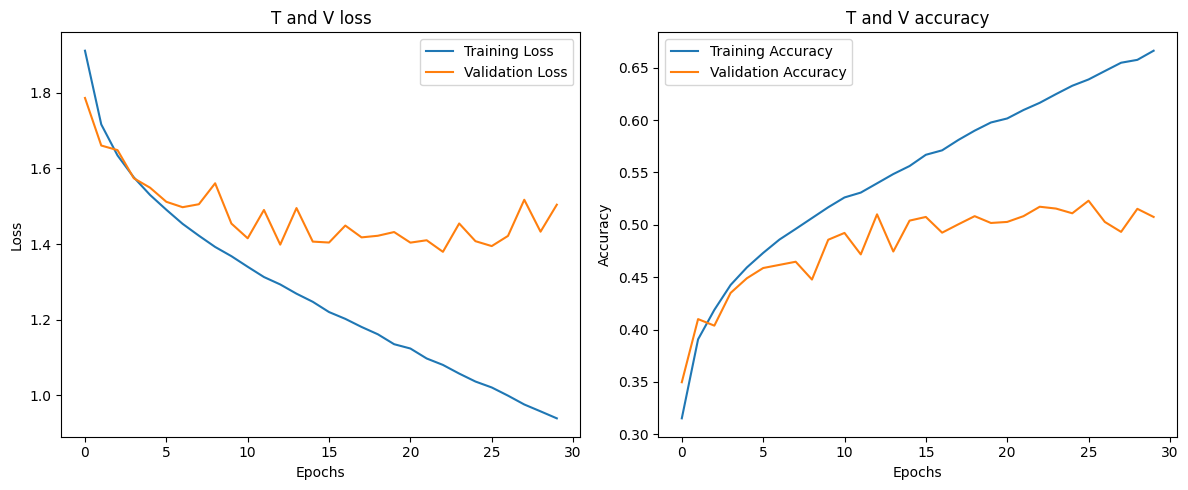

In [30]:
#plotting
plt.figure(figsize=(12, 5))

#Loss
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label = "Training Loss")
plt.plot(history.history['val_loss'], label = "Validation Loss")
plt.title("T and V loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

#Loss
plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label = "Training Accuracy")
plt.plot(history.history['val_accuracy'], label = "Validation Accuracy")
plt.title("T and V accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()